# 04. コモンファクター（core）

`exposures/core/{ym}.csv` のコモンファクターを使います。ファクターのタイプは `exposures/fc_list.csv` にあります。

レポートの設定（`core_exposures`）は、ユニバースの全銘柄について、欠損（−100 以下）を除いて Blom スコアにし、
欠損は 0 で埋めます。

In [1]:
import pandas as pd

from p_ken import charts, factors, io
from p_ken.stats import annualized

START, END = "2026-01-01", "2026-09-30"  # 計算期間（年初来）
Q_START = "2026-07-01"  # 強調する四半期の初日
HIGHLIGHT = (Q_START, END)


def pct(x):
    """表示用：小数のリターンを +1.23% 形式の文字列に。"""
    return x.map("{:+.2%}".format)

## 1. ファクターとタイプの一覧

In [2]:
fl = factors.core_factor_list("gemq")
print(len(fl), "factors")
fl.groupby("type", sort=False).variable.agg(["count", lambda s: ", ".join(s)]).set_axis(
    ["count", "factors"], axis=1
)

115 factors


,count,factors
type,,
Stock Value,2,"BP_EST, BP_ACT"
Flow Value,18,"EP_EST, EP_ACT, DP_EST, DP_ACT, SP_EST, SP_ACT..."
Profitability,26,"ROE_EST, ROE_ACT, ROA_EST, ROA_ACT, ROIC_EST, ..."
Growth,11,"LTG, SALES_GRW, OI_GRW, EPS_GRW, NI_GRW, PPE_G..."
Shareholder Return,5,"CSI, DOE, EISS, DISS, NPOP"
Momentum,9,"REV1P, REV1R, REV3P, REV3R, MOM1, MOM12, MOM12..."
Volatility,2,"VOLA60, SKEW60"
Other,1,ILLIQ
Financial Quality,29,"ACC_BS, ACC_CF, XFIN_BS, XFIN_CF, XFIN_SP, CUR..."


## 2. 一部のファクターだけ計算する

In [3]:
src = factors.core_exposures("gemq", ["BP_EST", "EP_EST", "ROE_EST", "MOM12"])
daily = factors.regression_returns("gemq", src, START, END)
annualized(daily).round(4)

,start,end,days,total,ann_ret,ann_risk,hit,rr
BP_EST,2026-01-01,2026-09-30,195,0.0113,0.0146,0.0709,0.4923,0.2065
EP_EST,2026-01-01,2026-09-30,195,0.0354,0.0457,0.0699,0.4821,0.6541
ROE_EST,2026-01-01,2026-09-30,195,0.0373,0.0482,0.0301,0.5487,1.6020
MOM12,2026-01-01,2026-09-30,195,0.0804,0.1039,0.0967,0.5795,1.0743


## 3. タイプ平均（レポートのコモンファクター図）

`core_factor_returns` で全ファクターを計算し、`type_returns` でタイプごとに単純平均します。

In [4]:
all_daily = factors.core_factor_returns("gemq", START, END)
by_type = factors.type_returns(all_daily, "gemq")
print(all_daily.shape, "->", by_type.shape)
pct(by_type.loc[Q_START:].sum().to_frame("2026/07/01 - 09/30"))

(195, 103) -> (195, 9)


,2026/07/01 - 09/30
Stock Value,+7.47%
Flow Value,+6.01%
Profitability,+0.46%
Growth,-1.90%
Shareholder Return,+0.76%
Momentum,-3.86%
Volatility,-4.59%
Other,+3.79%
Financial Quality,-0.44%


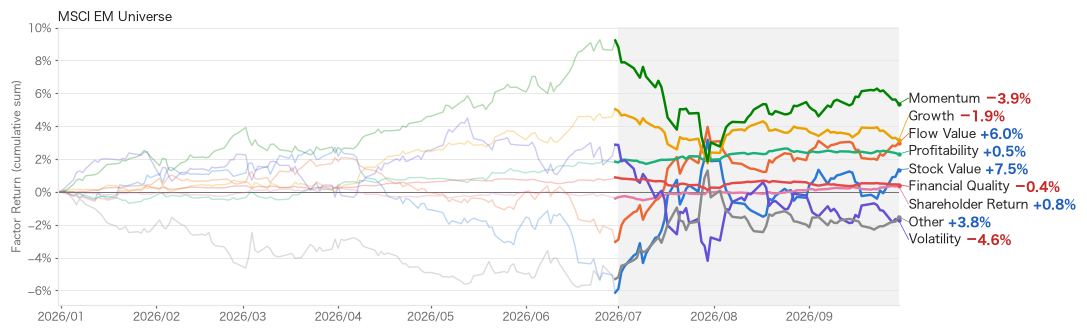

In [5]:
fig = charts.plot_cumulative(by_type, START, HIGHLIGHT, "MSCI EM Universe", dpi=110)

## 4. 自作の合成ファクター

Stock Value / Flow Value タイプの全ファクターの z スコアを平均した Value 合成を作ります。
月ごとの関数を `factors.monthly` で包むだけです。

In [6]:
from p_ken.stats import zscore


def value_composite(ym: str) -> pd.DataFrame:
    cols = fl.loc[fl.type.isin(["Stock Value", "Flow Value"]), "variable"].tolist()
    bids = io.load_universe("gemq", ym).bid
    core = io.load_core("gemq", ym).set_index("bid").reindex(bids)
    x = core[[c for c in cols if c in core.columns]]
    return pd.DataFrame({"value_composite": zscore(x).mean(axis=1)}).rename_axis("bid")


comp = factors.regression_returns("gemq", factors.monthly(value_composite), START, END)
pct(
    pd.DataFrame(
        {
            "value_composite": comp.loc[Q_START:, "value_composite"].sum(),
            **{t: by_type.loc[Q_START:, t].sum() for t in ["Stock Value", "Flow Value"]},
        },
        index=["2026/07/01 - 09/30"],
    ).T
)

,2026/07/01 - 09/30
value_composite,+9.62%
Stock Value,+7.47%
Flow Value,+6.01%
